# 04 · Policies and offline A/B test

Phase 2 found that narrow feeds pay off within a session but predict a quieter next day, and that long runs of the same tag hurt right away. Phase 3 found that the most relevant model is also the narrowest, at 3.9 distinct tags per 10 videos.

Here I test re-ranking policies on top of that baseline. Every policy is scored on the small matrix, where the real outcome of almost every user and video pair is known. So this is an offline A/B test with real reactions, not simulated ones.

| Arm | What changes |
|---|---|
| A. Baseline | Top 10 by the debiased LightGBM score |
| B. Random exploration | Slots 4 and 8 get random videos |
| C. Triggered injection (the proposal) | If the user's last 20 videos are narrow (Narrowness Index at or above 0.378), slots 4 and 8 get the best-scoring videos from two *adjacent* tags the user rarely watches. For every user, a streak breaker stops a 5th same-tag video in a row, counting their history |
| C0. Streak breaker only | Arm C without the injection |
| E. Adjacent for everyone | Arm C's injection applied to every user, no trigger, no streak breaker |
| D. MMR | Greedy re-rank that penalises repeating a tag, tuned to the same diversity as C |
| F. MMR + triggered | MMR ordering, then C's discovery slots for narrow users, then the streak breaker |

**Adjacent tags** are learned from data. Two tags are adjacent when the same people watch both (correlation of tag shares across 7,176 users). A tag counts as new to a user when it is under 3% of their history. **User state** (narrowness, trailing streak, tag history) comes only from each user's big-matrix history, which is what a live system would know before serving the feed.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.metrics import evaluate, author_tiers, paired_bootstrap
from src import policies as P

ART = ROOT / "data" / "models"
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREY, GREEN = "#3b6ea8", "#c0392b", "#8a8a8a", "#2e8b57"

if not (ART / "user_state.npz").exists():
    P.step_state()
z = np.load(ART / "small_scores.npz")
st = dict(np.load(ART / "user_state.npz"))
truth, Q = z["truth"], z["truth_q"]
ptag, author, views = z["ptag"], z["author"], z["item_views_big"]
secs = np.expm1(z["log_duration"]) / 1000
S = P.masked(z["lgbm_debiased"], truth)
U, I = S.shape
assert (st["users"] == z["users"]).all()
tiers = author_tiers(views, author)

## 1. Who gets triggered

Users whose last 20 videos are narrow (>= 0.378): 497 of 1,411 (35%)
Users ending their history on a run of 4+ same-tag videos: 0.6%
count    1411.000
mean        0.359
std         0.062
min         0.196
10%         0.285
50%         0.354
90%         0.441
max         0.682


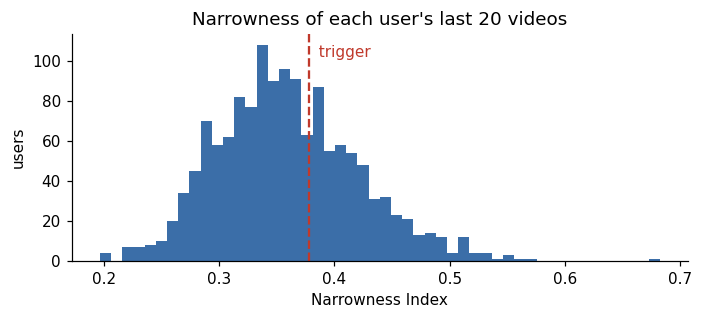

In [2]:
trig = st["narrow"] >= P.NARROW_TRIGGER
print(f"Users whose last 20 videos are narrow (>= {P.NARROW_TRIGGER}): {trig.sum():,} of {U:,} ({trig.mean():.0%})")
print(f"Users ending their history on a run of 4+ same-tag videos: {(st['tail_len'] >= 4).mean():.1%}")
print(pd.Series(st["narrow"]).describe(percentiles=[.1, .5, .9]).round(3).to_string())

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.hist(st["narrow"], bins=50, color=BLUE)
ax.axvline(P.NARROW_TRIGGER, color=RED, ls="--")
ax.text(P.NARROW_TRIGGER, ax.get_ylim()[1] * .9, "  trigger", color=RED)
ax.set(title="Narrowness of each user's last 20 videos", xlabel="Narrowness Index", ylabel="users")
fig.tight_layout(); fig.savefig(FIG / "04_trigger.png")

## 2. Run the arms

In [3]:
arms = {}
arms["A. Baseline"] = P.baseline(S)
arms["B. Random exploration"] = P.random_explore(S)
arms["C. Triggered injection"] = P.triggered(S, ptag, st)
arms["C0. Streak breaker only"] = P.triggered(S, ptag, st, inject=False)
arms["E. Adjacent for everyone"] = P.adjacent_all(S, ptag, st)

def evalarm(top):
    return evaluate(top, Q, truth, ptag, author, views, tiers, secs)

per_user, rows = {}, {}
for name, (top, inj) in arms.items():
    per_user[name], rows[name] = evalarm(top)
target_tags = rows["C. Triggered injection"]["distinct_tags"]
print(f"Arm C reaches {target_tags:.2f} distinct tags per list")

Arm C reaches 4.51 distinct tags per list


MMR has one knob, the penalty for repeating a tag. A fair comparison sets it so MMR reaches the same average diversity as arm C. Then the question is simply which method gives up less relevance for the same variety.

In [4]:
grid = {}
for lam in [0.0, 0.002, 0.005, 0.01, 0.02, 0.04, 0.08]:
    top, _ = P.mmr(S, ptag, lam)
    grid[lam] = evalarm(top)[1]["distinct_tags"]
g = pd.Series(grid)
print(g.round(2).to_string())
lo, hi = g[g <= target_tags].index.max(), g[g >= target_tags].index.min()
for _ in range(8):
    mid = (lo + hi) / 2
    if evalarm(P.mmr(S, ptag, mid)[0])[1]["distinct_tags"] < target_tags: lo = mid
    else: hi = mid
lam_star = hi
arms["D. MMR (matched)"] = P.mmr(S, ptag, lam_star)
per_user["D. MMR (matched)"], rows["D. MMR (matched)"] = evalarm(arms["D. MMR (matched)"][0])

F = "F. MMR + triggered"
arms[F] = P.mmr_triggered(S, ptag, st, lam_star)
per_user[F], rows[F] = evalarm(arms[F][0])
print(f"\nMMR penalty matched to arm C: {lam_star:.4f} -> {rows['D. MMR (matched)']['distinct_tags']:.2f} tags")

0.000    3.86
0.002    4.11
0.005    4.52
0.010    5.03
0.020    5.81
0.040    6.78
0.080    7.92



MMR penalty matched to arm C: 0.0048 -> 4.51 tags


## 3. Results

In [5]:
order = ["A. Baseline", "B. Random exploration", "C0. Streak breaker only", "C. Triggered injection",
         "E. Adjacent for everyone", "D. MMR (matched)", "F. MMR + triggered"]
new_slots = {n: P.new_to_user(arms[n][0], ptag, st["hist_share"]) for n in order}
for n in order:
    per_user[n]["new_to_user"] = new_slots[n]
res = pd.DataFrame(rows).T.loc[order]
res["changed_slots"] = [arms[n][1].mean() * 10 for n in order]
res["new_to_user"] = [new_slots[n].mean() for n in order]
res["new_to_user_narrow"] = [new_slots[n][trig].mean() for n in order]
cols = ["rel", "ndcg", "watch_secs", "distinct_tags", "ild", "new_to_user", "new_to_user_narrow",
        "creator_gini", "authors_reached", "catalog_coverage", "changed_slots"]
res[cols].round(3)

,rel,ndcg,watch_secs,distinct_tags,ild,new_to_user,new_to_user_narrow,creator_gini,authors_reached,catalog_coverage,changed_slots
A. Baseline,0.561,0.571,8.513,3.870,0.625,1.930,1.964,0.970,248.0,0.080,0.000
B. Random exploration,0.552,0.563,8.526,4.826,0.727,2.068,2.179,0.878,1408.0,0.604,2.000
C0. Streak breaker only,0.563,0.572,8.576,4.070,0.672,2.038,2.111,0.970,241.0,0.078,0.376
C. Triggered injection,0.559,0.569,8.487,4.507,0.702,2.562,3.598,0.969,263.0,0.085,0.936
E. Adjacent for everyone,0.555,0.566,8.479,5.296,0.755,3.557,3.598,0.969,265.0,0.085,1.997
D. MMR (matched),0.563,0.572,8.583,4.510,0.731,2.210,2.290,0.972,231.0,0.075,0.970
F. MMR + triggered,0.560,0.569,8.530,5.020,0.772,2.776,3.849,0.970,246.0,0.080,1.488


Two kinds of variety are tracked. `distinct_tags` and `ild` measure variety inside the list. `new_to_user` counts slots (out of 10) in tags under 3% of that user's history, i.e. genuinely new territory, and `new_to_user_narrow` is the same for the 35% of users the trigger fires on. Phase 2 says the long-run cost comes from a narrowing diet, so new territory is the variety that matters most.

Every difference below is paired by user (the same 1,411 people see every arm) with a 95% bootstrap interval. `rel` is the length-adjusted relevance (0.5 = random). `watch_secs` is expected seconds watched per recommended video.

In [6]:
base = "A. Baseline"
diffs = []
for name in order[1:]:
    for m in ["rel", "watch_secs", "distinct_tags", "new_to_user"]:
        d, lo_, hi_ = paired_bootstrap(per_user[base][m], per_user[name][m])
        diffs.append({"arm": name, "metric": m, "diff": d, "lo": lo_, "hi": hi_,
                      "pct": d / per_user[base][m].mean() * 100})
D = pd.DataFrame(diffs)
D.pivot(index="arm", columns="metric", values="pct").loc[order[1:]].round(2).rename(
    columns=lambda c: c + " %chg")

metric,distinct_tags %chg,new_to_user %chg,rel %chg,watch_secs %chg
arm,,,,
B. Random exploration,24.70,7.16,-1.57,0.15
C0. Streak breaker only,5.16,5.62,0.38,0.73
C. Triggered injection,16.44,32.76,-0.31,-0.31
E. Adjacent for everyone,36.84,84.32,-0.99,-0.40
D. MMR (matched),16.52,14.54,0.36,0.82
F. MMR + triggered,29.70,43.85,-0.22,0.20


In [7]:
D.round(4)

,arm,metric,diff,lo,hi,pct
0,B. Random exploration,rel,-0.0088,-0.0117,-0.0060,-1.5749
1,B. Random exploration,watch_secs,0.0128,-0.0628,0.0764,0.1498
2,B. Random exploration,distinct_tags,0.9561,0.9114,1.0007,24.7024
3,B. Random exploration,new_to_user,0.1382,0.0936,0.1828,7.1612
4,C0. Streak breaker only,rel,0.0022,0.0002,0.0041,0.3842
5,C0. Streak breaker only,watch_secs,0.0624,-0.0038,0.1611,0.7333
6,C0. Streak breaker only,distinct_tags,0.1999,0.1729,0.2261,5.1639
7,C0. Streak breaker only,new_to_user,0.1084,0.0829,0.1339,5.6188
8,C. Triggered injection,rel,-0.0018,-0.0042,0.0006,-0.3131
9,C. Triggered injection,watch_secs,-0.0260,-0.0903,0.0296,-0.3052


## 4. Price of variety

The useful comparison is not "did relevance drop?". Any change to the baseline's top 10 will lower it. The question is how much relevance each arm gives up per extra tag of variety.

In [8]:
r0, t0 = res.loc[base, "rel"], res.loc[base, "distinct_tags"]
price = pd.DataFrame({
    "extra_tags": res.distinct_tags - t0,
    "rel_lost": r0 - res.rel,
    "watch_secs_change": res.watch_secs - res.loc[base, "watch_secs"],
}).drop(base)
price["rel_lost_per_tag"] = price.rel_lost / price.extra_tags
price.round(4)

,extra_tags,rel_lost,watch_secs_change,rel_lost_per_tag
B. Random exploration,0.9561,0.0088,0.0128,0.0092
C0. Streak breaker only,0.1999,-0.0022,0.0624,-0.0108
C. Triggered injection,0.6364,0.0018,-0.0260,0.0028
E. Adjacent for everyone,1.4259,0.0056,-0.0338,0.0039
D. MMR (matched),0.6393,-0.0020,0.0694,-0.0031
F. MMR + triggered,1.1495,0.0013,0.0171,0.0011


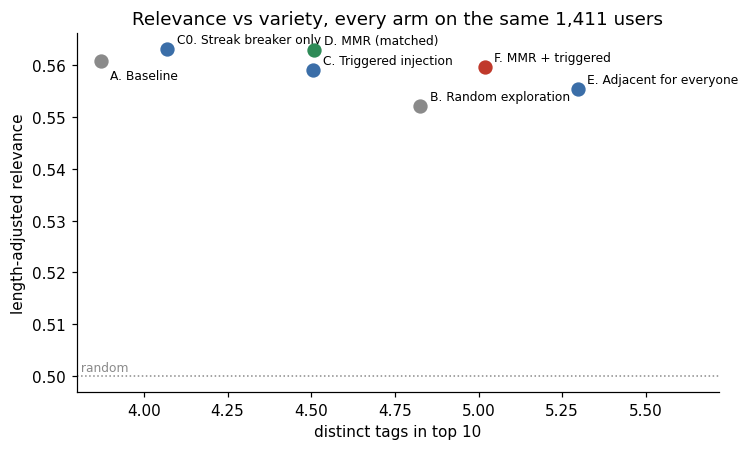

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.2))
colors = {base: GREY, "B. Random exploration": GREY, "C0. Streak breaker only": BLUE,
          "C. Triggered injection": BLUE, "E. Adjacent for everyone": BLUE, "D. MMR (matched)": GREEN,
          "F. MMR + triggered": RED}
for n in order:
    ax.scatter(res.loc[n, "distinct_tags"], res.loc[n, "rel"], s=70, color=colors[n], zorder=3)
    off = (6, -12) if n == base else (6, 4)
    ax.annotate(n, (res.loc[n, "distinct_tags"], res.loc[n, "rel"]), xytext=off,
                textcoords="offset points", fontsize=8)
ax.set_xlim(right=ax.get_xlim()[1] + 0.35)
ax.axhline(0.5, color=GREY, ls=":", lw=1); ax.text(ax.get_xlim()[0], 0.501, " random", color=GREY, fontsize=8)
ax.set(title="Relevance vs variety, every arm on the same 1,411 users",
       xlabel="distinct tags in top 10", ylabel="length-adjusted relevance")
fig.tight_layout(); fig.savefig(FIG / "04_arms_tradeoff.png")

## 5. Familiar variety vs new territory

MMR and targeted injection reach the same number of tags per list, but not the same kind. MMR spreads the list across tags the user already watches. Injection reaches tags they rarely touch. The chart counts slots in new territory for the users whose feeds are narrow.

D. MMR (matched)             new-territory slots for narrow users: +0.33 [+0.27, +0.38] vs baseline
C. Triggered injection       new-territory slots for narrow users: +1.63 [+1.58, +1.69] vs baseline
F. MMR + triggered           new-territory slots for narrow users: +1.89 [+1.82, +1.95] vs baseline


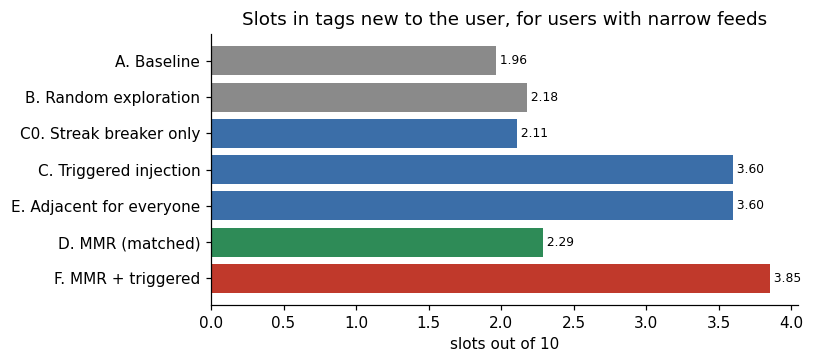

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
v = res.loc[order, "new_to_user_narrow"]
ax.barh(range(len(order)), v, color=[colors[n] for n in order])
ax.set_yticks(range(len(order)), order); ax.invert_yaxis()
for i, x in enumerate(v):
    ax.text(x, i, f" {x:.2f}", va="center", fontsize=8)
ax.set(title="Slots in tags new to the user, for users with narrow feeds", xlabel="slots out of 10")
fig.tight_layout(); fig.savefig(FIG / "04_new_territory.png")

for n in ["D. MMR (matched)", "C. Triggered injection", F]:
    d, lo_, hi_ = paired_bootstrap(new_slots[base][trig], new_slots[n][trig])
    print(f"{n:28s} new-territory slots for narrow users: {d:+.2f} [{lo_:+.2f}, {hi_:+.2f}] vs baseline")

## 6. Are the injected videos any good?

A slot spent on discovery is only a cost if the video in it does worse than the one it replaced. Because the small matrix is fully observed, I can check each injected video's real outcome against two things. One is the baseline videos it displaced, the ones that fell off the end of the list. The other is a random video in the same slot.

In [11]:
def slot_outcomes(name):
    top, inj = arms[name]
    q_inj = np.take_along_axis(Q, top, 1)[inj]
    wr_inj = np.take_along_axis(truth, top, 1)[inj]
    base_top = arms[base][0]
    displaced = np.array([[i not in set(top[u]) for i in base_top[u]] for u in range(U)])
    q_disp = np.take_along_axis(Q, base_top, 1)[displaced]
    return {"injected slots": int(inj.sum()), "q injected": np.nanmean(q_inj), "q displaced": np.nanmean(q_disp),
            "share injected above typical (q>0.5)": np.nanmean(q_inj > .5),
            "share injected watched fully": np.nanmean(wr_inj >= 1),
            "new tags per injected slot": np.mean([ptag[i] not in set(ptag[arms[base][0][u]])
                                                   for u in range(U) for i in top[u][inj[u]]])}
slots = pd.DataFrame({n: slot_outcomes(n) for n in ["B. Random exploration", "E. Adjacent for everyone",
                                                    "C. Triggered injection", "D. MMR (matched)", F]}).T
slots.round(3)

,injected slots,q injected,q displaced,share injected above typical (q>0.5),share injected watched fully,new tags per injected slot
B. Random exploration,2822.0,0.506,0.551,0.513,0.334,0.712
E. Adjacent for everyone,2818.0,0.520,0.555,0.524,0.531,0.939
C. Triggered injection,1321.0,0.516,0.560,0.524,0.519,0.857
D. MMR (matched),1368.0,0.546,0.558,0.561,0.560,0.681
F. MMR + triggered,2099.0,0.529,0.557,0.542,0.520,0.823


## 7. Who pays and who gains

In [12]:
c = F
g = pd.DataFrame({"triggered": trig,
                  "rel_change": per_user[c].rel - per_user[base].rel,
                  "tags_change": per_user[c].distinct_tags - per_user[base].distinct_tags,
                  "secs_change": per_user[c].watch_secs - per_user[base].watch_secs,
                  "new_change": per_user[c].new_to_user - per_user[base].new_to_user})
by = g.groupby("triggered").agg(users=("rel_change", "size"), rel_change=("rel_change", "mean"),
                                tags_change=("tags_change", "mean"), new_territory_change=("new_change", "mean"),
                                secs_change=("secs_change", "mean"))
by.index = by.index.map({False: "not triggered (MMR + breaker)", True: "triggered (MMR + discovery + breaker)"})
by.round(4)

,users,rel_change,tags_change,new_territory_change,secs_change
triggered,,,,,
not triggered (MMR + breaker),914,0.0013,0.6729,0.2812,0.0102
triggered (MMR + discovery + breaker),497,-0.0060,2.0262,1.8853,0.0298


## 8. Creators

In [13]:
tt = pd.DataFrame({n: {"head": rows[n]["head_share"], "mid": rows[n]["mid_share"], "tail": rows[n]["tail_share"],
                       "authors reached": rows[n]["authors_reached"], "creator Gini": rows[n]["creator_gini"],
                       "videos reached": int(round(rows[n]["catalog_coverage"] * I))} for n in order}).T
tt.round(3)

,head,mid,tail,authors reached,creator Gini,videos reached
A. Baseline,0.027,0.154,0.819,248.0,0.970,267.0
B. Random exploration,0.036,0.195,0.769,1408.0,0.878,2011.0
C0. Streak breaker only,0.029,0.158,0.813,241.0,0.970,258.0
C. Triggered injection,0.025,0.150,0.825,263.0,0.969,282.0
E. Adjacent for everyone,0.020,0.141,0.839,265.0,0.969,284.0
D. MMR (matched),0.032,0.158,0.810,231.0,0.972,249.0
F. MMR + triggered,0.029,0.154,0.817,246.0,0.970,266.0


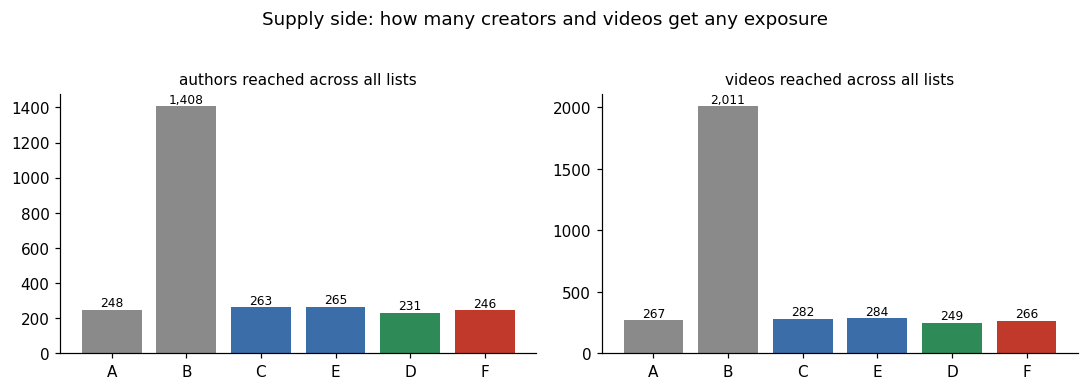

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
show = [base, "B. Random exploration", "C. Triggered injection", "E. Adjacent for everyone", "D. MMR (matched)", F]
short = ["A", "B", "C", "E", "D", "F"]
for ax, (m, lab) in zip(axes, [("authors reached", "authors reached across all lists"),
                               ("videos reached", "videos reached across all lists")]):
    v = tt.loc[show, m].astype(float)
    ax.bar(short, v, color=[GREY, GREY, BLUE, BLUE, GREEN, RED])
    ax.set_title(lab, fontsize=10)
    for i, x in enumerate(v):
        ax.text(i, x, f"{x:,.0f}", ha="center", va="bottom", fontsize=8)
fig.suptitle("Supply side: how many creators and videos get any exposure", y=1.03)
fig.tight_layout(); fig.savefig(FIG / "04_creators.png", bbox_inches="tight")

## 9. Save

In [15]:
out = {"arms": {n: {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else int(v))
                    for k, v in rows[n].items()} for n in order},
       "diffs_vs_baseline": D.round(5).to_dict("records"),
       "slot_outcomes": slots.round(4).to_dict("index"),
       "new_to_user_narrow": res.new_to_user_narrow.round(3).to_dict(),
       "triggered_users": int(trig.sum()), "users": int(U), "mmr_lambda": lam_star}
(ROOT / "reports" / "phase4_results.json").write_text(json.dumps(out, indent=2, default=float))
np.savez_compressed(ART / "phase4_lists.npz", **{n.split(".")[0]: arms[n][0] for n in order},
                    **{n.split(".")[0] + "_inj": arms[n][1] for n in order})
print("saved")

saved


## Takeaways

1. **My first proposal lost to the textbook method.** At the same number of tags per list (4.5), MMR keeps relevance flat while triggered injection costs 0.3%. Neither difference is significant, but on list variety alone there was no case for the custom policy.
2. **But the two buy different kinds of variety.** MMR spreads the list across tags the user already watches. For narrow users it adds only about 0.3 slots of new territory per page. Triggered injection adds about 1.6, close to double the baseline. Phase 2 put the long-run cost on a narrowing diet, so new territory is the variety that matters.
3. **Combining them gives the best of both.** F (MMR, then discovery slots for narrow users, then the streak breaker) reaches about 5 tags per list (+30%) and nearly doubles new territory for narrow users, with no significant relevance loss (−0.2%, interval includes zero). Watch time is unchanged. The small relevance cost falls on the narrow users who get the discovery slots (about −1% for them), while everyone else gains slightly from MMR and the streak breaker. This is the policy I would ship to a live test.
4. **The streak breaker on its own is free.** It *raises* relevance slightly (+0.4%, significant) and adds 5% more tags. The baseline was over-repeating, which matches Phase 2.
5. **Discovery slots cost little.** Injected adjacent-tag videos score a little below the videos they pushed out (0.53 vs 0.56 on the 0–1 relevance scale) but above random picks (0.51), and get watched fully far more often than random picks (52% vs 33%). Adjacent tags are where exploration is cheapest.
6. **Creators barely move.** Tag variety does not spread exposure across authors much (Gini 0.97 throughout). Only random exploration does, and it pays for that with relevance. Creator spread needs its own lever, not a side effect of tag diversity.

**What this test cannot show.** It scores one feed page against real outcomes. The next-day effect of a broader diet comes from Phase 2's observational estimate, and is combined with these results in Phase 5.